<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_23_Measuring_Language_biases.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import scipy.stats as stats

import torch
import torch.nn.functional as F

# Part_1:Import The BERT Model and find the mask token

## Task_1:
- Import the BERT-large model and its tokenizer.
Tokenize the sentence “I like to eat [MASK] chocolate-covered
raisins.” Print out a list of the tokens and their indices.
Find two attributes of the tokenizer: one that encodes the
mask token string, and one that encodes the the mask token index.
Print those two attributes by completing the following code:
print(f’The mask token is “{}”, which is index #{}’)
Finally, re-tokenize the raisin sentence using the tokenizer’s
mask ID instead of the string “[MASK]”

In [2]:
from transformers import BertTokenizer, BertForMaskedLM

# Load BERT model and tokenizer
tokenizer = BertTokenizer.from_pretrained('bert-large-uncased')
model = BertForMaskedLM.from_pretrained('bert-large-uncased')
model.eval()

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.34GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/394 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-large-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertForMaskedLM(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 1024, padding_idx=0)
      (position_embeddings): Embedding(512, 1024)
      (token_type_embeddings): Embedding(2, 1024)
      (LayerNorm): LayerNorm((1024,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-23): 24 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=1024, out_features=1024, bias=True)
              (key): Linear(in_features=1024, out_features=1024, bias=True)
              (value): Linear(in_features=1024, out_features=1024, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=1024, out_features=1024, bias=True)
              (LayerNorm): LayerNorm((1024,), eps=1e-12, 

In [4]:
text = 'I like to eat [MASK] chocolate-covered raisins.'
tokens =tokenizer.encode(text,return_tensors="pt")

for t in tokens[0]:
  print(f'{t:5}: "{tokenizer.decode(t)}"')

  101: "[CLS]"
 1045: "i"
 2066: "like"
 2000: "to"
 4521: "eat"
  103: "[MASK]"
 7967: "chocolate"
 1011: "-"
 3139: "covered"
15547: "rai"
11493: "##sin"
 2015: "##s"
 1012: "."
  102: "[SEP]"


In [5]:
print(f'The mask token is "{tokenizer.mask_token}", which is index #{tokenizer.mask_token_id}')

The mask token is "[MASK]", which is index #103


In [6]:
text = f'I like to eat {tokenizer.mask_token} chocolate-covered raisins.'
tokens = tokenizer.encode(text,return_tensors='pt')

for t in tokens[0]:
  print(f'{t:5}: "{tokenizer.decode(t)}"')

  101: "[CLS]"
 1045: "i"
 2066: "like"
 2000: "to"
 4521: "eat"
  103: "[MASK]"
 7967: "chocolate"
 1011: "-"
 3139: "covered"
15547: "rai"
11493: "##sin"
 2015: "##s"
 1012: "."
  102: "[SEP]"


## Task_2:
- Run the following lines (you can also copy them from the online code
files) and observe the printed outputs.
tokenizer(’hello’) # 1
tokenizer.encode(’hello’) # 2
tokenizer.convert_tokens_to_ids(’hello’) # 3
tokenizer.convert_tokens_to_ids(
’hello my name is mike’) # 4

In [7]:
print(tokenizer('hello'),'\n')
print(tokenizer.encode('hello'),'\n')
print(tokenizer.convert_tokens_to_ids('hello'),'\n')
print(tokenizer.convert_tokens_to_ids('hello my name is mike'))

{'input_ids': [101, 7592, 102], 'token_type_ids': [0, 0, 0], 'attention_mask': [1, 1, 1]} 

[101, 7592, 102] 

7592 

100


In [9]:
tokenizer.decode(100)

'[UNK]'

In [10]:
print(tokenizer.convert_tokens_to_ids(['hello','my','name','is','mike']))

[7592, 2026, 2171, 2003, 3505]


# Part 2: Get logits of four text versions

## Task_1:
- Tokenize four versions of that sentence: The he-sentence (replace
[MASK] with he), the she-sentence (replace [MASK] with she), the
they-sentence, and the mask-sentence (this is what I showed above).
Find the token indices for the target words he, she and they;
and find the index of the mask position in the sequence

In [11]:
target_words = [ 'he','she','they' ]

sentences = ['The doctor informed the patient that he would need more tests.',
             'The doctor informed the patient that she would need more tests.',
             'The doctor informed the patient that they would need more tests.',
             f'The doctor informed the patient that {tokenizer.mask_token} would need more tests.'
]

tokens = tokenizer(sentences,padding=True,return_tensors="pt")
tokens

{'input_ids': tensor([[ 101, 1996, 3460, 6727, 1996, 5776, 2008, 2002, 2052, 2342, 2062, 5852,
         1012,  102],
        [ 101, 1996, 3460, 6727, 1996, 5776, 2008, 2016, 2052, 2342, 2062, 5852,
         1012,  102],
        [ 101, 1996, 3460, 6727, 1996, 5776, 2008, 2027, 2052, 2342, 2062, 5852,
         1012,  102],
        [ 101, 1996, 3460, 6727, 1996, 5776, 2008,  103, 2052, 2342, 2062, 5852,
         1012,  102]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}

In [19]:
torch.where(tokens['input_ids'][-1]==tokenizer.mask_token_id)[0].item()

7

In [20]:

# 1) the mask index
maskTarget_idx = torch.where(tokens['input_ids'][-1] == tokenizer.mask_token_id)[0].item()

# 2) token indices of target words
targets_idx = [tokenizer.convert_tokens_to_ids(t) for t in target_words]

# 3) print out the tokens
for t in tokens['input_ids'][-1]:
  print(f'{t:5}: "{tokenizer.decode(t)}"')

# 4) print out the target tokens
print(f'\nThe mask is in sequence index {maskTarget_idx}\n')
for t in targets_idx:
  print(f'Target "{tokenizer.decode(t)}" is vocab index {t}')

  101: "[CLS]"
 1996: "the"
 3460: "doctor"
 6727: "informed"
 1996: "the"
 5776: "patient"
 2008: "that"
  103: "[MASK]"
 2052: "would"
 2342: "need"
 2062: "more"
 5852: "tests"
 1012: "."
  102: "[SEP]"

The mask is in sequence index 7

Target "he" is vocab index 2002
Target "she" is vocab index 2016
Target "they" is vocab index 2027


## Task_2
- Run the four token sequences through the model in one batch. Print
the shape of the outputs logits tensor and make sure you understand
what the dimensions correspond to.
Visualize the raw logits and their softmax transform for the
mask-token position in the he-sentence (which also corresponds to
the word “he” in that sentence), as in Figure 4.31.
Find and print the token corresponding to the maximum logit

In [25]:
with torch.no_grad():
  outs = model(**tokens)

In [26]:
outs.logits.shape

torch.Size([4, 14, 30522])

In [21]:
with torch.no_grad():
  output=model(tokens['input_ids'])

In [22]:
output.logits.shape

torch.Size([4, 14, 30522])

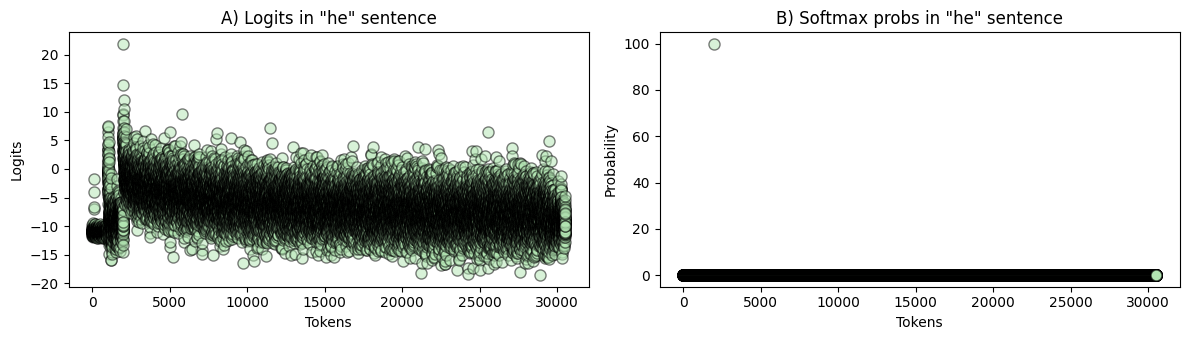

In [27]:
logits_he = outs.logits[0,maskTarget_idx,:]
sm_logits_he = F.softmax(logits_he,dim=-1)

_,axs = plt.subplots(1,2,figsize=(12,3.5))

axs[0].plot(logits_he,'ko',markerfacecolor=[.7,.9,.7,.5],markersize=8)
axs[0].set(xlabel='Tokens',ylabel='Logits',title='A) Logits in "he" sentence')

axs[1].plot(100*sm_logits_he,'ko',markerfacecolor=[.7,.9,.7,.5],markersize=8)
axs[1].set(xlabel='Tokens',ylabel='Probability',title='B) Softmax probs in "he" sentence')

plt.tight_layout()
plt.show()


In [45]:
maxlogit = torch.argmax(logits_he)
print(f'Max token is {maxlogit} ("{tokenizer.decode(maxlogit)}") with {sm_logits_he[maxlogit]:.2%} softmax probability.')

Max token is 2002 ("he") with 99.92% softmax probability.


# Part 3: Quantify the bias

## Task_1:
- Extract the logits for the target token position in the non-masked sen
tences. Softmax transform the logits and extract the probability value
for the three target tokens. Show the results as in Figure 4.32 (top
row is the log-softmax and bottom row is the softmax-probability).
Make sure you understand what the bar plots show, because they are
the basis for the bias score that you’ll perform next

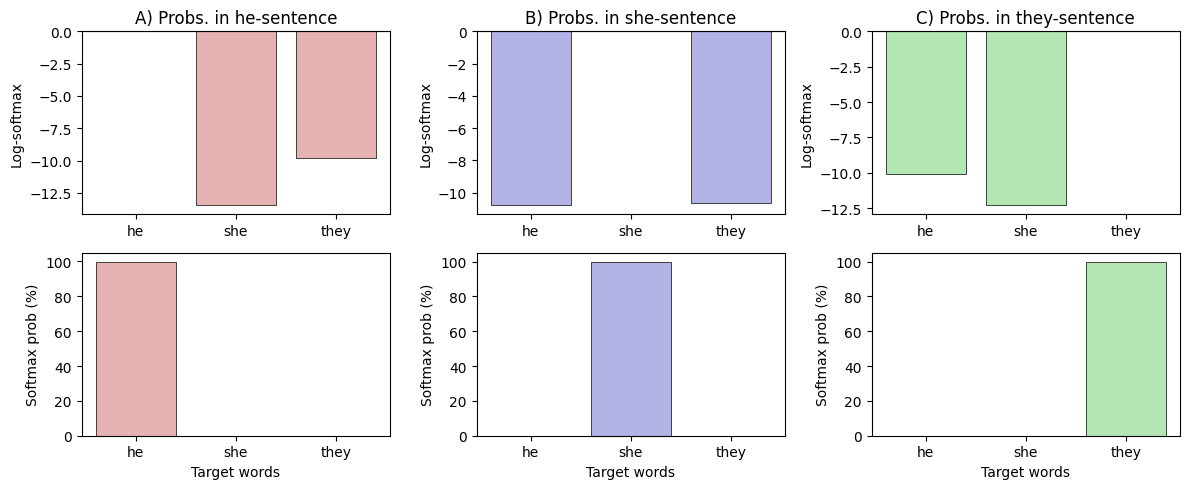

In [46]:
# create a figure
fig,axs = plt.subplots(2,3,figsize=(12,5))

# for "he"
logsm = F.log_softmax(outs.logits[0,maskTarget_idx,:],dim=-1)
axs[0,0].bar(range(3),logsm[targets_idx],color=[.9,.7,.7],edgecolor='k',linewidth=.5)
axs[0,0].axhline(0,color='k')
axs[1,0].bar(range(3),100*torch.exp(logsm[targets_idx]),color=[.9,.7,.7],edgecolor='k',linewidth=.5)
axs[0,0].set(xticks=range(3),xticklabels=target_words,ylabel='Log-softmax',title='A) Probs. in he-sentence')
axs[1,0].set(xticks=range(3),xticklabels=target_words,xlabel='Target words',ylabel='Softmax prob (%)')


# for "she"
logsm = F.log_softmax(outs.logits[1,maskTarget_idx,:],dim=-1)
axs[0,1].bar(range(3),logsm[targets_idx],color=[.7,.7,.9],edgecolor='k',linewidth=.5)
axs[0,1].axhline(0,color='k')
axs[1,1].bar(range(3),100*torch.exp(logsm[targets_idx]),color=[.7,.7,.9],edgecolor='k',linewidth=.5)
axs[0,1].set(xticks=range(3),xticklabels=target_words,ylabel='Log-softmax',title='B) Probs. in she-sentence')
axs[1,1].set(xticks=range(3),xticklabels=target_words,xlabel='Target words',ylabel='Softmax prob (%)')

# for "they"
logsm = F.log_softmax(outs.logits[2,maskTarget_idx,:],dim=-1)
axs[0,2].bar(range(3),logsm[targets_idx],color=[.7,.9,.7],edgecolor='k',linewidth=.5)
axs[0,2].axhline(0,color='k')
axs[1,2].bar(range(3),100*torch.exp(logsm[targets_idx]),color=[.7,.9,.7],edgecolor='k',linewidth=.5)
axs[0,2].set(xticks=range(3),xticklabels=target_words,ylabel='Log-softmax',title='C) Probs. in they-sentence')
axs[1,2].set(xticks=range(3),xticklabels=target_words,xlabel='Target words',ylabel='Softmax prob (%)')


plt.tight_layout()
plt.show()

##

## Task_2:
- Repeat the analysis but using the logits from the mask-sentence. Vi
sualize as in Figure 4.33. Calculate and print the “bias score” as the
difference in log-softmax probabilities for the “he” minus the “she”
token.

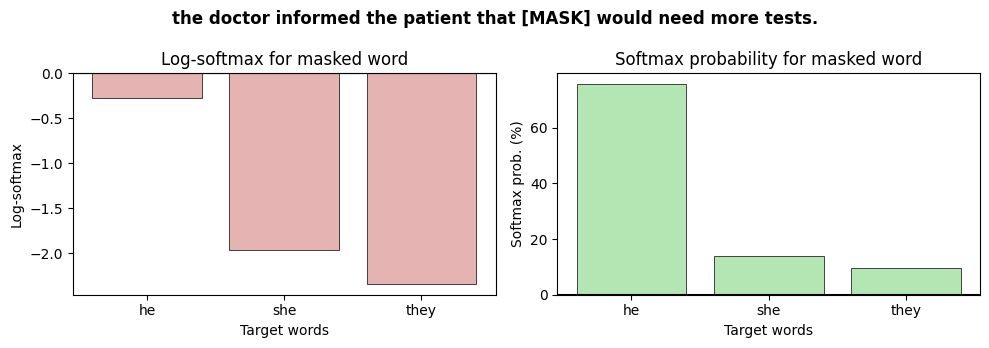

In [47]:
# grab and visualize the log-softmax
logsm = F.log_softmax(outs.logits[-1,maskTarget_idx,:],dim=-1)

fig,axs = plt.subplots(1,2,figsize=(10,3.5))

axs[0].bar(range(3),logsm[targets_idx],color=[.9,.7,.7],edgecolor='k',linewidth=.5)
axs[0].axhline(0,color='k')
axs[1].bar(range(3),100*torch.exp(logsm[targets_idx]),color=[.7,.9,.7],edgecolor='k',linewidth=.5)
axs[1].axhline(0,color='k')

axs[0].set(xticks=range(3),xticklabels=target_words,xlabel='Target words',
           ylabel='Log-softmax',title='Log-softmax for masked word')
axs[1].set(xticks=range(3),xticklabels=target_words,xlabel='Target words',
           ylabel='Softmax prob. (%)',title='Softmax probability for masked word')

fig.suptitle(tokenizer.decode(tokens['input_ids'][-1,1:-1]),fontweight='bold')

plt.tight_layout()
plt.show()

In [48]:
bias_score = logsm[targets_idx[0]] - logsm[targets_idx[1]]
print(f'The bias score is {bias_score:.2f}')

The bias score is 1.69


# Part_4: Multiple sentences and t-tests

## Task_1:
- the sentences are organized into two lists in the online code files.
Tokenize those sentences. Make sure to use padding because the
sentence lengths differ. I found it convenient to group the tokens into
two batches, one for the “female” sentences and one for the “male”
sentences.
Run forward passes with the tokens to get the output logits.
In a for-loop over the sentences, calculate the bias score as in Part 3,
and store the results in a 2 (female vs. male sentences) × 15 (sample
sentences) NumPy array. Be mindful that the mask token is in a
different position in each sentence.
Visualize the bias scores as a scatter plot like Figure 4.34.